In [1]:
%pip install -q langchain-core langchain-community langchain-text-splitters sentence-transformers faiss-cpu transformers sentencepiece

Note: you may need to restart the kernel to use updated packages.


In [2]:
documents = [
    {
        "title": "Gradient Descent",
        "text": """
        A machine learning model has parameters that change during training.
        A loss function measures how wrong the model's predictions are.
        Gradient descent uses gradients to determine how changes to model
        parameters affect the loss.
        It updates parameters in the direction that reduces the loss.
        The learning rate controls the size of each parameter update.
        A learning rate that is too large can cause the model to overshoot
        a good solution, while a learning rate that is too small can make
        training very slow.
        """
    },
    {
        "title": "Neural Networks",
        "text": """
        Neural networks consist of interconnected layers of artificial neurons.
        Each neuron receives numerical inputs, applies weights and a bias,
        and uses an activation function to produce an output.
        During training, neural networks learn patterns from examples by
        adjusting their weights and biases.
        The input layer receives the data, hidden layers process it, and
        the output layer produces the prediction.
        Deep learning uses neural networks with multiple hidden layers.
        These layers can learn increasingly complex patterns from data.
        """
    },
    {
        "title": "Transformers",
        "text": """
        Transformer models use attention mechanisms to represent relationships
        between tokens in a sequence.
        Attention allows a model to assign different importance to different
        tokens when processing a particular token.
        Transformers are widely used in natural language processing tasks,
        including text generation, translation, summarization, and semantic search.
        """
    }
]

In [3]:
print("Total source documents:", len(documents))

for doc in documents:
    print(f"- {doc['title']}")

Total source documents: 3
- Gradient Descent
- Neural Networks
- Transformers


In [4]:
# Converting the source document into a langchain document

from langchain_core.documents import Document

langchain_documents = [
    Document(
        page_content=doc['text'].strip(),
        metadata={"title": doc['title']}
    ) for doc in documents
]

In [5]:
print("Total langchain documents:", len(langchain_documents))
print(langchain_documents[0])

Total langchain documents: 3
page_content='A machine learning model has parameters that change during training.
        A loss function measures how wrong the model's predictions are.
        Gradient descent uses gradients to determine how changes to model
        parameters affect the loss.
        It updates parameters in the direction that reduces the loss.
        The learning rate controls the size of each parameter update.
        A learning rate that is too large can cause the model to overshoot
        a good solution, while a learning rate that is too small can make
        training very slow.' metadata={'title': 'Gradient Descent'}


In [6]:
# Breaking the documents into chunks to help the retrieval process

from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=250,
    chunk_overlap=40,
    length_function=len,
    separators=["\n\n","\n"," ",""]
)

chunks = text_splitter.split_documents(langchain_documents)

print("Total chunks:", len(chunks))

Total chunks: 8


In [7]:
for i, chunk in enumerate(chunks):
    print(f"\n--- Chunk {i + 1} ---")
    print("Title:", chunk.metadata["title"])
    print("Characters:", len(chunk.page_content))
    print(chunk.page_content)


--- Chunk 1 ---
Title: Gradient Descent
Characters: 250
A machine learning model has parameters that change during training.
        A loss function measures how wrong the model's predictions are.
        Gradient descent uses gradients to determine how changes to model
        parameters affect the loss.

--- Chunk 2 ---
Title: Gradient Descent
Characters: 167
parameters affect the loss.
        It updates parameters in the direction that reduces the loss.
        The learning rate controls the size of each parameter update.

--- Chunk 3 ---
Title: Gradient Descent
Characters: 168
A learning rate that is too large can cause the model to overshoot
        a good solution, while a learning rate that is too small can make
        training very slow.

--- Chunk 4 ---
Title: Neural Networks
Characters: 208
Neural networks consist of interconnected layers of artificial neurons.
        Each neuron receives numerical inputs, applies weights and a bias,
        and uses an activation functio

In [8]:
# Intitalizing the embedding model

from langchain_community.embeddings import HuggingFaceEmbeddings

embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

/tmp/ipykernel_49/3919546479.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import HuggingFaceEmbeddings
/tmp/ipykernel_49/3919546479.py:5: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = HuggingFaceEmbeddings(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [9]:
# Converting the chunks into embeddings

# chunk_texts = [chunk.page_content for chunk in chunks]
# chunk_embeddings = embedding_model.embed_documents(chunk_texts)

# print("Total chunks:", len(chunk_texts))
# print("Total embeddings:", len(chunk_embeddings))
# print("Dimensions per embedding:", len(chunk_embeddings[0]))

In [10]:
# Initializing the vector store

from langchain_community.vectorstores import FAISS

vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embedding_model
)

print("Vector store created successfully!")
print("Total indexed chunks:", vector_store.index.ntotal)

Vector store created successfully!
Total indexed chunks: 8


In [11]:
# Testing similarity search

query = "How does a model learn to make fewer mistakes?"

results = vector_store.similarity_search_with_score(
    query,
    k=3
)

for document, score in results:
    print(f"\nTitle: {document.metadata['title']}")
    print(f"Distance: {score:.4f}")
    print(document.page_content)


Title: Gradient Descent
Distance: 1.0727
A learning rate that is too large can cause the model to overshoot
        a good solution, while a learning rate that is too small can make
        training very slow.

Title: Neural Networks
Distance: 1.2076
During training, neural networks learn patterns from examples by
        adjusting their weights and biases.
        The input layer receives the data, hidden layers process it, and
        the output layer produces the prediction.

Title: Gradient Descent
Distance: 1.2091
parameters affect the loss.
        It updates parameters in the direction that reduces the loss.
        The learning rate controls the size of each parameter update.


In [12]:
# Creating a retriever for retrieving the relevant chunks

retriever = vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={"k":3}
)

print("Retriever created succesfully")

Retriever created succesfully


In [13]:
query = "How does a model learn to make fewer mistakes?"

retrieved_documents = retriever.invoke(query)

print("Retrieved chunks:", len(retrieved_documents))

for i, document in enumerate(retrieved_documents, start=1):
    print(f"\n--- Result {i} ---")
    print("Title:", document.metadata["title"])
    print(document.page_content)

Retrieved chunks: 3

--- Result 1 ---
Title: Gradient Descent
A learning rate that is too large can cause the model to overshoot
        a good solution, while a learning rate that is too small can make
        training very slow.

--- Result 2 ---
Title: Neural Networks
During training, neural networks learn patterns from examples by
        adjusting their weights and biases.
        The input layer receives the data, hidden layers process it, and
        the output layer produces the prediction.

--- Result 3 ---
Title: Gradient Descent
parameters affect the loss.
        It updates parameters in the direction that reduces the loss.
        The learning rate controls the size of each parameter update.


In [14]:
# Loading the language model

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
generator = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model loaded!")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model loaded!


In [16]:
%pip install -q langchain-huggingface

Note: you may need to restart the kernel to use updated packages.


In [17]:
from langchain_core.prompts import PromptTemplate

prompt_template = PromptTemplate.from_template("""
Answer the question using only the context below.
If the context is insufficient, say so.
Keep the answer concise.

Context:
{context}

Question: {question}

Answer:
""")

In [18]:
import torch
from langchain_core.language_models.llms import LLM

class FlanT5Adapter(LLM):
    model: object
    tokenizer: object
    max_new_tokens: int = 100

    @property
    def _llm_type(self) -> str:
        return "flan-t5-custom"

    def _call(self, prompt: str, stop=None, **kwargs) -> str:
        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        )

        # Put inputs on the same device as the model
        device = next(self.model.parameters()).device
        inputs = {key: value.to(device) for key, value in inputs.items()}

        with torch.no_grad():
            outputs = self.model.generate(
                **inputs,
                max_new_tokens=self.max_new_tokens,
                do_sample=False
            )

        return self.tokenizer.decode(
            outputs[0],
            skip_special_tokens=True
        )

llm_chain_model = FlanT5Adapter(
    model=generator,
    tokenizer=tokenizer
)

In [19]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate

prompt_template = PromptTemplate.from_template("""
Answer the question using the context below.
Give a concise, complete answer based on the context.
If the context does not contain enough information, say so.

Context:
{context}

Question: {question}

Answer:
""")

rag_generation_chain = (
    prompt_template
    | llm_chain_model
    | StrOutputParser()
)

print("Generation chain created successfully!")


Generation chain created successfully!


In [20]:
test_result = rag_generation_chain.invoke({
    "context": (
        "Gradient descent uses gradients to determine how "
        "parameter changes affect loss. It updates parameters "
        "in a direction that reduces the loss."
    ),
    "question": "What does gradient descent do?"
})

print(test_result)


Updates parameters in a direction that reduces the loss.


In [21]:
# Testing the generation with the model

def rag_pipeline(query):
    
    retrieved_documents = retriever.invoke(query)
    
    context = "\n\n".join(
        f"Source: {doc.metadata['title']}\n{doc.page_content}"
        for doc in retrieved_documents
    )

    answer = rag_generation_chain.invoke({
        "context": context,
        "question": query
    })
    
    return {
        "question": query,
        "context": context,
        "answer": answer
    }

In [22]:
print("Answer:", rag_pipeline("Whats the meaning of gradient descent?")['answer'])

Answer: to determine how changes to model parameters affect the loss


In [23]:
%pip install -q langgraph

Note: you may need to restart the kernel to use updated packages.


In [24]:
# Defining the state of a langgraph

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class RAGState(TypedDict):
    question: str
    context: str
    answer: str
    retry_count: int

print("RAG state defined!")

RAG state defined!


In [25]:
# Defining the retrieval node of the langgraph

def retrieve_node(state: RAGState) -> dict:
    # Retrieve relevant chunks for the user's question
    retrieved_documents = retriever.invoke(state["question"])

    # Combine the chunks into one context string
    context = "\n\n".join(
        f"Source: {doc.metadata['title']}\n{doc.page_content}"
        for doc in retrieved_documents
    )

    # Return the state update
    return {
        "context": context,
        "retry_count": state["retry_count"] + 1
    }

In [26]:
# Defining the generation node of the langgraph

def generate_node(state: RAGState) -> dict:
    answer = rag_generation_chain.invoke({
        "context": state["context"],
        "question": state["question"]
    })

    return {"answer": answer}

In [30]:
# Adding conditional edges to the graph

MAX_ATTEMPTS = 3

def route_after_retrieval(state: RAGState) -> str:
    # Check whether retrieval returned any context
    if state["context"].strip():
        return "generate"

    if state['retry_count'] < MAX_ATTEMPTS:
        return "retrieve"
    
    return "no_context"

In [31]:
def no_context_node(state: RAGState) -> dict:
    return {
        "answer": "I couldn't retrieve any context to answer this question."
    }

In [32]:
graph_builder = StateGraph(RAGState)

# Register the three nodes
graph_builder.add_node("retrieve", retrieve_node)
graph_builder.add_node("generate", generate_node)
graph_builder.add_node("no_context", no_context_node)

# Define the initial path
graph_builder.add_edge(START, "retrieve")

# Choose the next node based on the routing function
graph_builder.add_conditional_edges(
    "retrieve",
    route_after_retrieval,
    {
        "generate": "generate",
        "no_context": "no_context",
        "retrieve": "retrieve",
    }
)

# Both paths finish the workflow
graph_builder.add_edge("generate", END)
graph_builder.add_edge("no_context", END)

rag_graph = graph_builder.compile()

print("Conditional RAG graph compiled successfully!")


Conditional RAG graph compiled successfully!


In [33]:
result = rag_graph.invoke({
    "question": "What does gradient descent do?",
    "context": "",
    "answer": "",
    "retry_count": 0
})

print("Question:", result["question"])
print("Retrieval attempts:", result["retry_count"])
print("Answer:", result["answer"])


Question: What does gradient descent do?
Retrieval attempts: 1
Answer: Use gradients to determine how changes to model parameters affect the loss.


In [34]:
def empty_retrieve_node(state: RAGState) -> dict:
    return {
        "context": "",
        "retry_count": state["retry_count"] + 1
    }


test_builder = StateGraph(RAGState)

test_builder.add_node("retrieve", empty_retrieve_node)
test_builder.add_node("generate", generate_node)
test_builder.add_node("no_context", no_context_node)

test_builder.add_edge(START, "retrieve")

test_builder.add_conditional_edges(
    "retrieve",
    route_after_retrieval,
    {
        "generate": "generate",
        "retrieve": "retrieve",
        "no_context": "no_context"
    }
)

test_builder.add_edge("generate", END)
test_builder.add_edge("no_context", END)

test_graph = test_builder.compile()

test_result = test_graph.invoke({
    "question": "What does gradient descent do?",
    "context": "",
    "answer": "",
    "retry_count": 0
})

print("Retrieval attempts:", test_result["retry_count"])
print("Answer:", test_result["answer"])

Retrieval attempts: 3
Answer: I couldn't retrieve any context to answer this question.


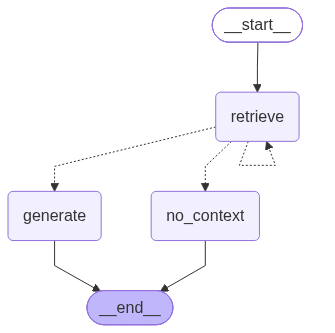

In [35]:
# Displaying the graph structure

from IPython.display import Image, display

graph_image = rag_graph.get_graph().draw_mermaid_png()
display(Image(graph_image))


In [36]:
# Implementing checkpoints in the existing cyclic graph

from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()

checkpointed_graph = graph_builder.compile(
    checkpointer=checkpointer
)

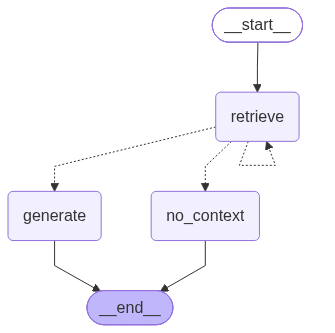

In [37]:
graph_image = checkpointed_graph.get_graph().draw_mermaid_png()
display(Image(graph_image))


In [38]:
config = {
    "configurable": {
        "thread_id": "rag-session-1"
    }
}

result = checkpointed_graph.invoke(
    {
        "question": "What does gradient descent do?",
        "context": "",
        "answer": "",
        "retry_count": 0
    },
    config=config
)

print("Answer:", result["answer"])
print("Retrieval attempts:", result["retry_count"])

Answer: Use gradients to determine how changes to model parameters affect the loss.
Retrieval attempts: 1


In [39]:
snapshot = checkpointed_graph.get_state(config)

print("Saved state:")
print(snapshot.values)

Saved state:
{'question': 'What does gradient descent do?', 'context': "Source: Gradient Descent\nA machine learning model has parameters that change during training.\n        A loss function measures how wrong the model's predictions are.\n        Gradient descent uses gradients to determine how changes to model\n        parameters affect the loss.\n\nSource: Gradient Descent\nparameters affect the loss.\n        It updates parameters in the direction that reduces the loss.\n        The learning rate controls the size of each parameter update.\n\nSource: Neural Networks\nDuring training, neural networks learn patterns from examples by\n        adjusting their weights and biases.\n        The input layer receives the data, hidden layers process it, and\n        the output layer produces the prediction.", 'answer': 'Use gradients to determine how changes to model parameters affect the loss.', 'retry_count': 1}


#### Simulating how a tool would work in langgraph

In [42]:
# Simulating tool function

def multiply_numbers(a: float, b: float) -> float:
    """Multiply two numbers and return the result."""
    return a * b

In [40]:
class ToolState(TypedDict):
    question: str
    tool_result: float
    answer: str

In [44]:
def decide_tool_node(state: ToolState) -> dict:
    # Simulate the LLM deciding to use the calculator
    return {"tool_result": 0.0}


def calculator_node(state: ToolState) -> dict:
    # Execute the calculator using the requested numbers
    result = multiply_numbers(125, 48)
    return {"tool_result": result}


def answer_node(state: ToolState) -> dict:
    prompt = f"""
    Answer the question using the tool result below.
    Do not recalculate the result.

    Question: {state["question"]}
    Tool result: {state["tool_result"]}

    Answer:
    """

    answer = llm_chain_model.invoke(prompt)

    return {"answer": answer}

In [45]:
tool_builder = StateGraph(ToolState)

tool_builder.add_node("decide", decide_tool_node)
tool_builder.add_node("calculator", calculator_node)
tool_builder.add_node("answer", answer_node)

tool_builder.add_edge(START, "decide")
tool_builder.add_edge("decide", "calculator")
tool_builder.add_edge("calculator", "answer")
tool_builder.add_edge("answer", END)

tool_graph = tool_builder.compile()

In [46]:
result = tool_graph.invoke({
    "question": "What is 125 multiplied by 48?",
    "tool_result": 0.0,
    "answer": ""
})

print("Question:", result["question"])
print("Tool result:", result["tool_result"])
print("Answer:", result["answer"])

Question: What is 125 multiplied by 48?
Tool result: 6000
Answer: 125


In [47]:
def direct_answer_node(state: ToolState) -> dict:
    return {
        "answer": "This question does not require the calculator."
    }

In [48]:
def route_question(state: ToolState) -> str:
    question = state["question"].lower()

    if "multiplied by" in question or "times" in question:
        return "calculator"

    return "direct_answer"

In [49]:
conditional_builder = StateGraph(ToolState)

conditional_builder.add_node("calculator", calculator_node)
conditional_builder.add_node("answer", answer_node)
conditional_builder.add_node("direct_answer", direct_answer_node)

conditional_builder.add_conditional_edges(
    START,
    route_question,
    {
        "calculator": "calculator",
        "direct_answer": "direct_answer"
    }
)

conditional_builder.add_edge("calculator", "answer")
conditional_builder.add_edge("answer", END)
conditional_builder.add_edge("direct_answer", END)

conditional_tool_graph = conditional_builder.compile()

In [50]:
result = conditional_tool_graph.invoke({
    "question": "What is 125 multiplied by 48?",
    "tool_result": 0.0,
    "answer": ""
})

print(result)

{'question': 'What is 125 multiplied by 48?', 'tool_result': 6000, 'answer': '125'}


In [51]:
result = conditional_tool_graph.invoke({
    "question": "Tell me something about neural networks.",
    "tool_result": 0.0,
    "answer": ""
})

print(result)

{'question': 'Tell me something about neural networks.', 'tool_result': 0.0, 'answer': 'This question does not require the calculator.'}
